# Bike Sharing

**Задача:** исследовать почасовой спрос на прокат велосипедов и определить, что может помешать прогнозу числа аренд до начала часа.

**Источник:** [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), файл `hour.csv`. Для запуска CSV должен лежать рядом с ноутбуком. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, типы, первые строки и статистики.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("hour.csv", parse_dates=["dteday"])
print("Размер:", df.shape)
display(df.head())

Размер: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
df.info()
display(df.describe(include="all").T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


В файле 17 379 строк и 17 столбцов. `cnt` - целевая переменная; `instant` - номер записи; `dteday` - дата. Календарные категории (`season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday`, `weathersit`) представлены числами. `temp`, `atemp`, `hum` и `windspeed` нормированы.

## 2. Таргет

Распределение числа аренд в час. Проверяются также крайние значения и отсутствие нулевых наблюдений.

count    17379.00
mean       189.46
std        181.39
min          1.00
25%         40.00
50%        142.00
75%        281.00
max        977.00
Name: cnt, dtype: float64
cnt = 0: 0


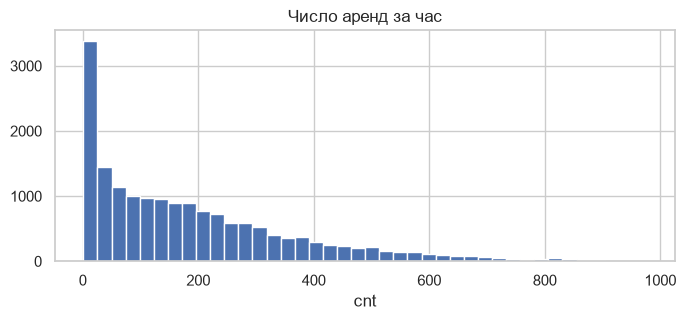

In [3]:
print(df["cnt"].describe().round(2))
print("cnt = 0:", df["cnt"].eq(0).sum())
df["cnt"].hist(bins=40, figsize=(8, 3))
plt.title("Число аренд за час")
plt.xlabel("cnt")
plt.show()

`cnt` изменяется от 1 до 977, медиана - 142, среднее - 189,46. Нулевых значений нет; отсутствие строки в некоторые часы не следует автоматически заменять на ноль. Исходная постановка - регрессия для неотрицательного счётчика.

## 3. Пропуски, дубликаты и временная сетка

Формальные пропуски и полные дубликаты проверяются отдельно от отсутствующих часов.

In [4]:
print("Всего NaN:", df.isna().sum().sum())
print("Полных дубликатов:", df.duplicated().sum())
print("Повторов даты и часа:", df.duplicated(["dteday", "hr"]).sum())
print("Период:", df["dteday"].min().date(), "-", df["dteday"].max().date())
print("Дней:", df["dteday"].nunique())

Всего NaN: 0
Полных дубликатов: 0
Повторов даты и часа: 0
Период: 2011-01-01 - 2012-12-31
Дней: 731


In [5]:
time = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
expected = pd.date_range(time.min(), time.max(), freq="h")
missing_hours = expected.difference(pd.DatetimeIndex(time))
per_day = df.groupby("dteday").size()
print("Отсутствующих часов:", len(missing_hours))
print("Дней с 24 записями:", per_day.eq(24).sum())
print("Дней с менее чем 24 записями:", per_day.lt(24).sum())
display(per_day.nsmallest(8).rename("Часов в данных"))

Отсутствующих часов: 165
Дней с 24 записями: 655
Дней с менее чем 24 записями: 76


dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
2011-08-28    17
2011-02-22    18
2011-08-27    18
Name: Часов в данных, dtype: int64

Формальных `NaN` и дубликатов нет. За период 2011-01-01 - 2012-12-31 отсутствуют 165 часовых записей; неполные сутки встречаются в 76 днях. Самый короткий день в файле - 2012-10-29 (одна запись). Причина отсутствия часов не указана.

## 4. Значения и потенциальные ошибки

Коды категорий, диапазоны нормированных признаков и специальные значения проверяются отдельно.

In [6]:
checks = {
    "Отрицательный cnt": df["cnt"].lt(0).sum(),
    "Час вне 0–23": (~df["hr"].between(0, 23)).sum(),
    "Месяц вне 1–12": (~df["mnth"].between(1, 12)).sum(),
    "Погода вне 1–4": (~df["weathersit"].between(1, 4)).sum(),
}
checks["Нормированные значения вне 0–1"] = ((df[["temp", "atemp", "hum", "windspeed"]] < 0) | (df[["temp", "atemp", "hum", "windspeed"]] > 1)).sum().sum()
print(pd.Series(checks))
print("hum = 0:", df["hum"].eq(0).sum())
display(df.loc[df["hum"].eq(0), "dteday"].value_counts())

Отрицательный cnt                 0
Час вне 0–23                      0
Месяц вне 1–12                    0
Погода вне 1–4                    0
Нормированные значения вне 0–1    0
dtype: int64
hum = 0: 22


dteday
2011-03-10    22
Name: count, dtype: int64

Нарушений проверенных диапазонов нет. Нулевая влажность (`hum=0`) встречается 22 раза, все - 2011-03-10.

## 5. Распределения числовых величин и IQR

`cnt` исследуется как счётчик; для погоды приведены распределения. Общий IQR не применяется к календарным категориям.

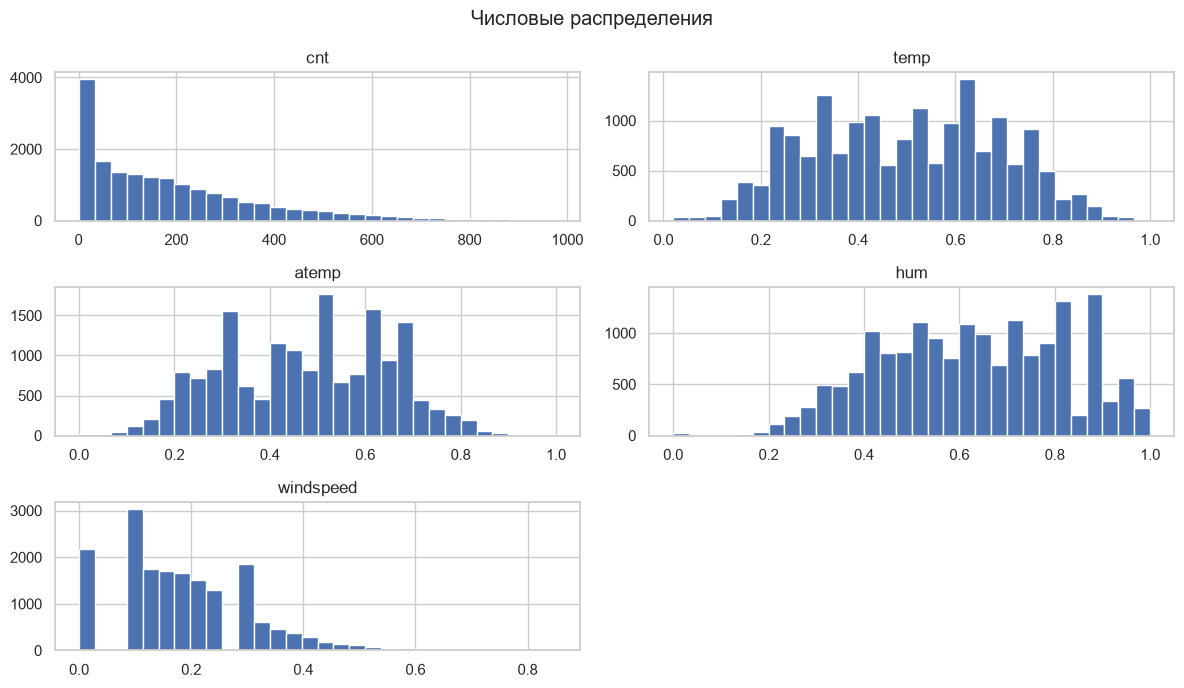

In [7]:
cols = ["cnt", "temp", "atemp", "hum", "windspeed"]
df[cols].hist(bins=30, figsize=(12, 7))
plt.suptitle("Числовые распределения")
plt.tight_layout()
plt.show()

In [9]:
for col in ["cnt", "windspeed"]:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    flagged = df[col].lt(q1 - 1.5 * iqr) | df[col].gt(q3 + 1.5 * iqr)
    print(col, "IQR-сигналы:", flagged.sum(), f"({100 * flagged.mean():.2f}%)")

cnt IQR-сигналы: 505 (2.91%)
windspeed IQR-сигналы: 342 (1.97%)


По IQR отмечено 505 часовых значений `cnt` (2,91%) и 342 значения `windspeed` (1,97%). Для спроса высокие пики допустимы. Распределения погодных величин неравномерны.

## 6. Категориальные признаки отдельно

Календарь и коды погоды сравниваются по частотам. `hr` и `mnth` здесь рассматриваются как категории, несмотря на тип `int`.

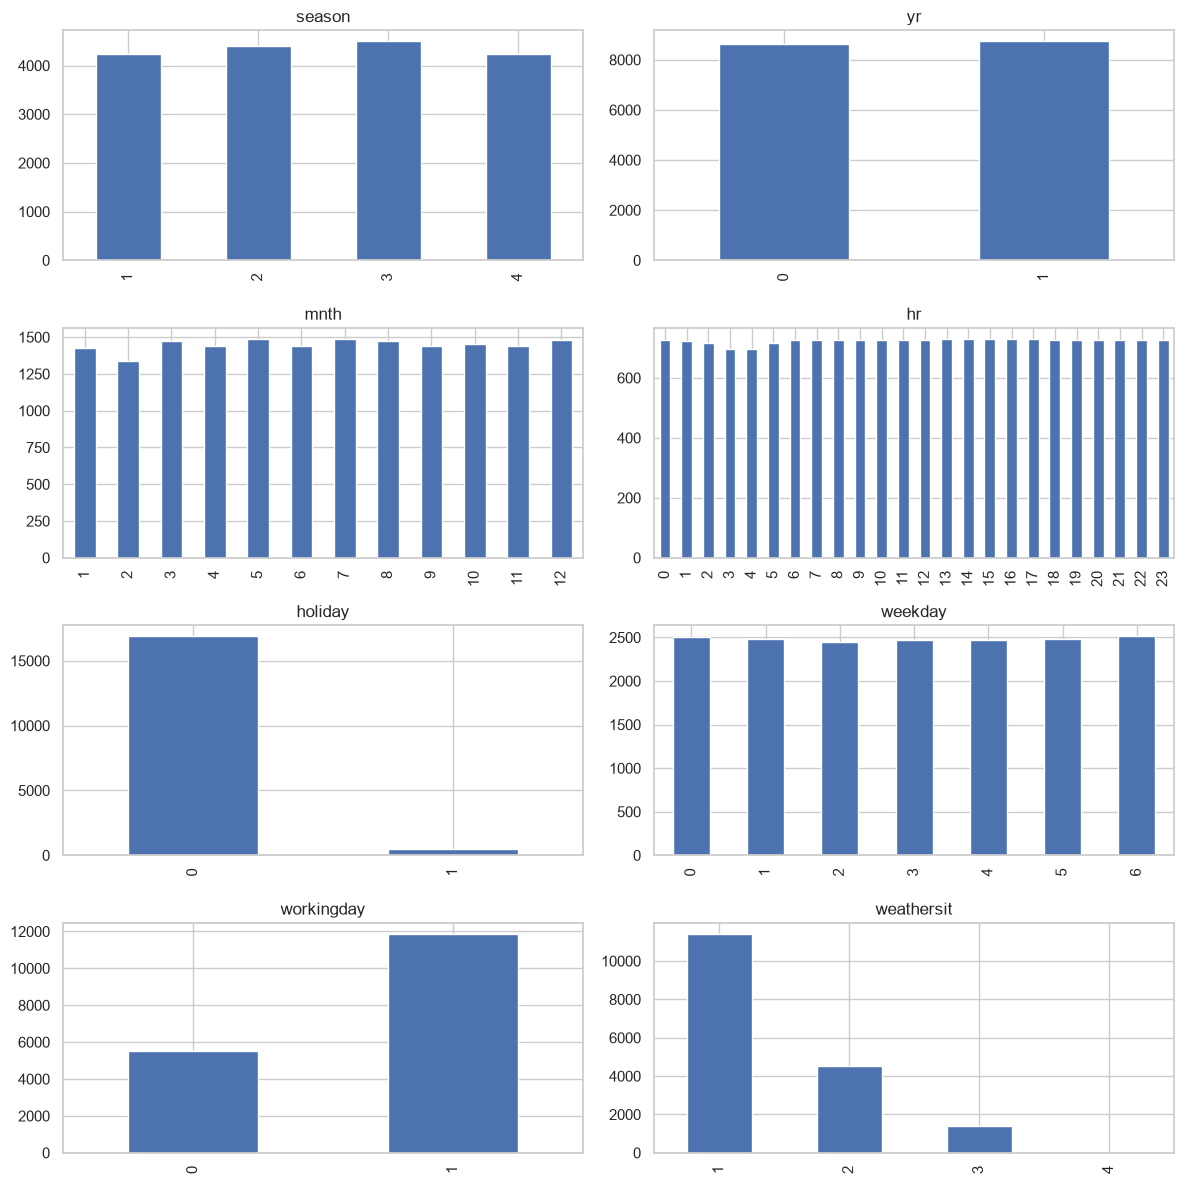

In [10]:
cat_cols = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit"]
fig, axes = plt.subplots(4, 2, figsize=(12, 12))
for col, ax in zip(cat_cols, axes.flat):
    df[col].value_counts().sort_index().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Категории сильно различаются по частоте: `weathersit=4` встречается всего трижды, `holiday=1` - 500 раз. Число записей по часам также неодинаково из-за пропусков в временной сетке.

## 7. Связь признаков со спросом

Количество наблюдений и среднее значение `cnt` для всех категориальных признаков.

In [11]:
for col in cat_cols:
    print("\n", col)
    display(df.groupby(col)["cnt"].agg(["size", "mean", "median"]).round(2))


 season


,size,mean,median
season,,,
1,4242,111.11,76.0
2,4409,208.34,165.0
3,4496,236.02,199.0
4,4232,198.87,155.5



 yr


,size,mean,median
yr,,,
0,8645,143.79,109.0
1,8734,234.67,191.0



 mnth


,size,mean,median
mnth,,,
1,1429,94.42,66.0
2,1341,112.87,82.0
3,1473,155.41,104.0
4,1437,187.26,136.0
5,1488,222.91,188.5
6,1440,240.52,203.0
7,1488,231.82,202.0
8,1475,238.10,204.0
9,1437,240.77,190.0


... (6 outputs left out)


 workingday


,size,mean,median
workingday,,,
0,5514,181.41,119.0
1,11865,193.21,151.0



 weathersit


,size,mean,median
weathersit,,,
1,11413,204.87,159.0
2,4544,175.17,133.0
3,1419,111.58,63.0
4,3,74.33,36.0


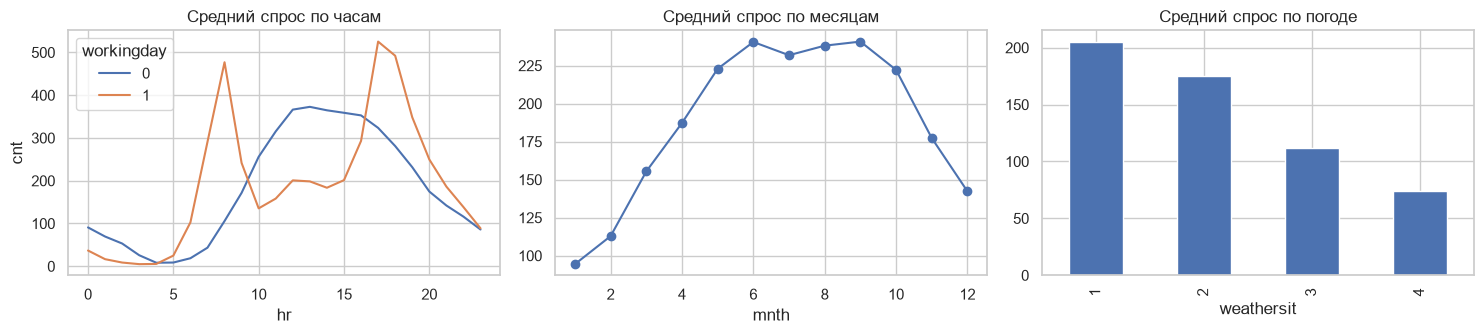

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sns.lineplot(data=df, x="hr", y="cnt", hue="workingday", estimator="mean", errorbar=None, ax=axes[0])
axes[0].set_title("Средний спрос по часам")
df.groupby("mnth")["cnt"].mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Средний спрос по месяцам")
df.groupby("weathersit")["cnt"].mean().plot.bar(ax=axes[2])
axes[2].set_title("Средний спрос по погоде")
plt.tight_layout()
plt.show()

Средний `cnt` по годам: 143,79 в 2011 и 234,67 в 2012. По часам общий максимум в 17:00 (461,45 аренды), минимум в 04:00 (6,35). В рабочие дни пик заметен также утром; в нерабочие - днём. Для `weathersit=1` среднее 204,87, для `weathersit=3` - 111,58. Группу `weathersit=4` нельзя надёжно интерпретировать по трём строкам.

## 8. Корреляции и парные распределения

Для сравнения используются измеряемые величины, временной индекс, компоненты спроса и таргет. С кодами календарных категорий корреляции не интерпретируются как линейная зависимость.

registered    0.972
casual        0.695
temp          0.405
atemp         0.401
instant       0.278
windspeed     0.093
hum          -0.323
Name: cnt, dtype: float64

temp / atemp: 0.988


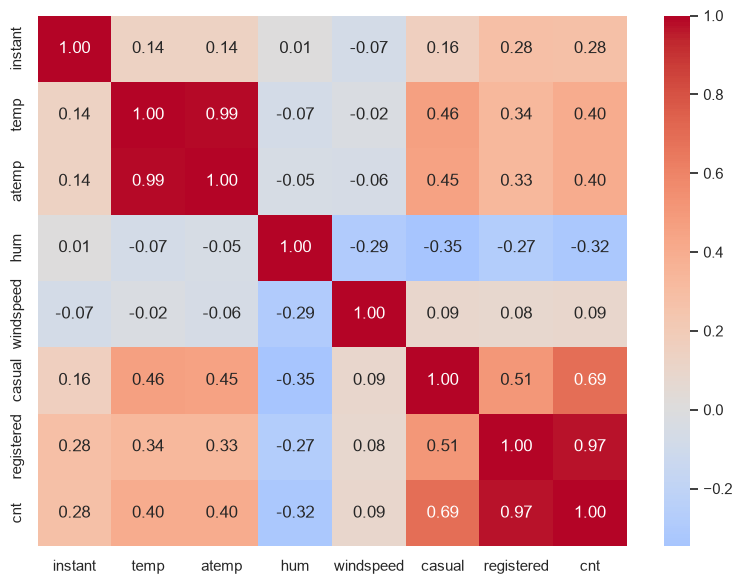

In [13]:
corr_cols = ["instant", "temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
corr = df[corr_cols].corr()
display(corr["cnt"].drop("cnt").sort_values(ascending=False).round(3))
print("temp / atemp:", round(df["temp"].corr(df["atemp"]), 3))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

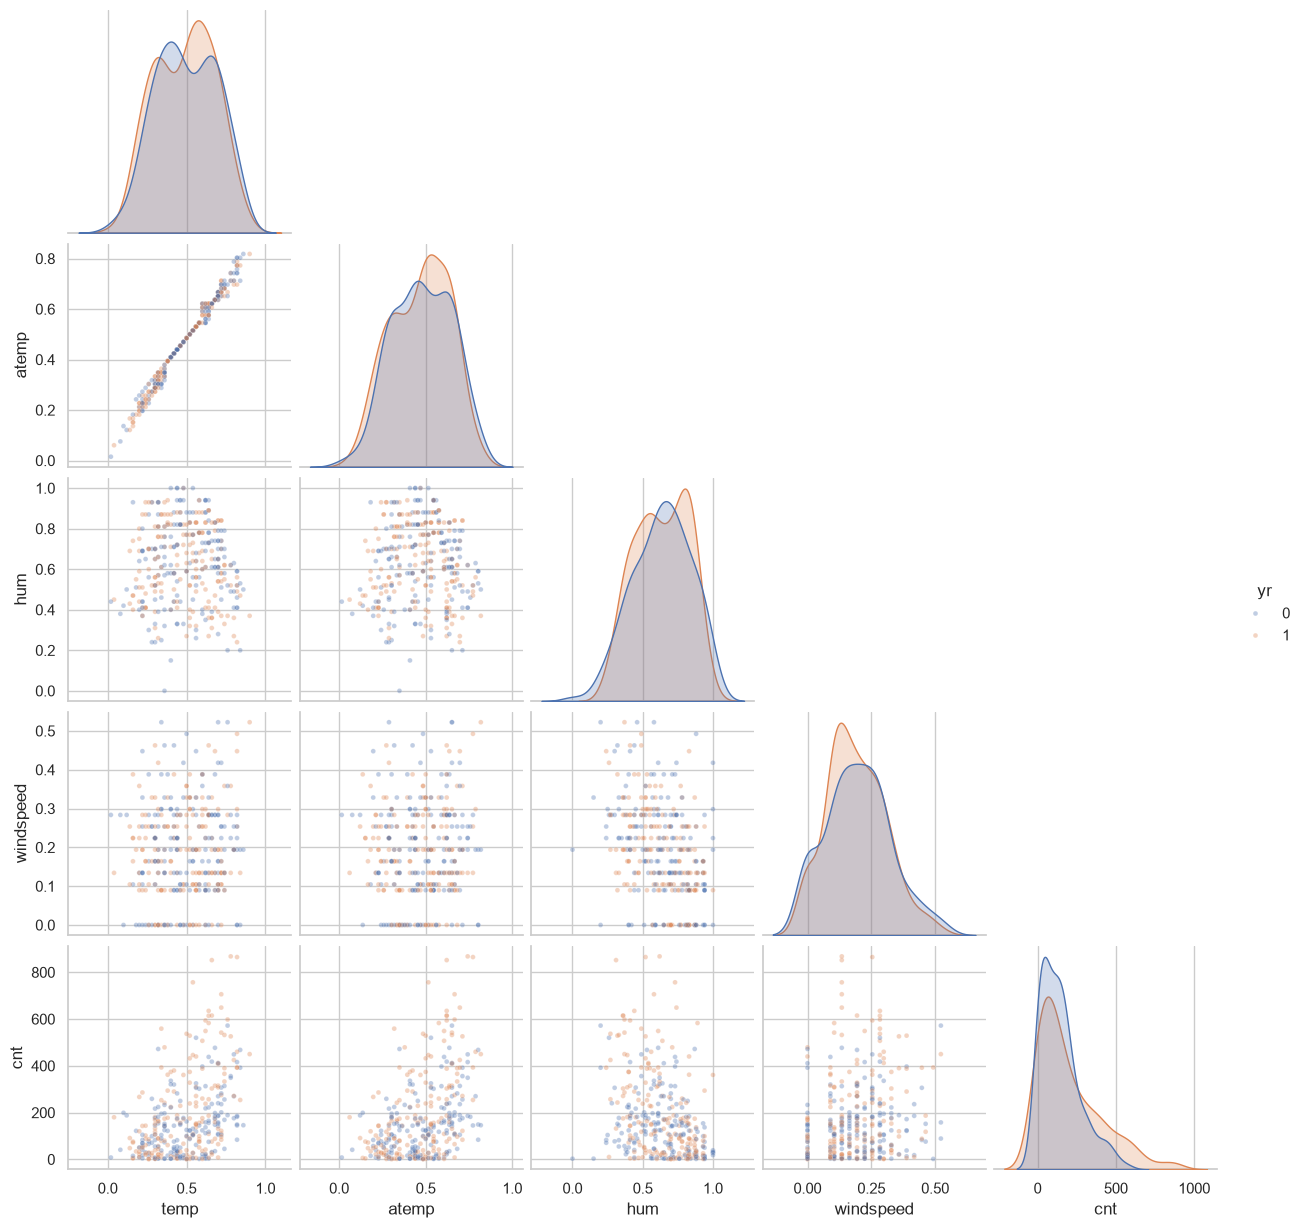

In [14]:
sample = df.sample(350, random_state=42)
sns.pairplot(sample, vars=["temp", "atemp", "hum", "windspeed", "cnt"],
             hue="yr", corner=True, plot_kws={"alpha": 0.35, "s": 12})
plt.show()

`temp` и `atemp` сильно коррелируют (r≈0,988). Корреляция `cnt` с `registered` ≈0,972, с `casual` ≈0,695. Эти два столбца требуют отдельной проверки на утечку.

## 9. Проверка утечки и временной структуры

Проверяется связь целевой переменной с компонентами спроса, а также согласованность календарных кодов.

In [16]:
print("cnt = casual + registered:", (df["cnt"] == df["casual"] + df["registered"]).sum(), "из", len(df))
print("instant идёт по порядку:", df["instant"].equals(pd.Series(range(1, len(df) + 1))))
print("yr соответствует дате:", ((df["dteday"].dt.year - 2011) == df["yr"]).all())
print("mnth соответствует дате:", (df["dteday"].dt.month == df["mnth"]).all())
print("weekday соответствует дате:", ((df["dteday"].dt.day_of_week + 1) % 7 == df["weekday"]).all())
display(df.groupby("yr")["cnt"].agg(["size", "mean", "median"]).round(2))

cnt = casual + registered: 17379 из 17379
instant идёт по порядку: True
yr соответствует дате: True
mnth соответствует дате: True
weekday соответствует дате: True


,size,mean,median
yr,,,
0,8645,143.79,109.0
1,8734,234.67,191.0


Во всех 17 379 строках `cnt = casual + registered`. Оба компонента становятся известны после фактических аренд и не подходят для прогноза спроса до начала часа. `instant` - порядковый индекс, а `dteday`, `yr`, `mnth`, `weekday` взаимосвязаны, календарные коды согласованы с датой. Для проверки прогноза будущих периодов требуется разбиение по времени.

## 10. Выводы и эталон для агента

1. **Цель:** `cnt` - число аренд за час. Постановка - регрессия.
2. **Пропуски:** `NaN` нет, но во временной сетке отсутствуют 165 часовых записей. Пустые часы не приравниваются к нулевому спросу.
3. **Необычные значения:** `hum=0` встречается 22 раза в один день; проверка первоисточника необходима. Автоматического удаления нет.
4. **Утечка:** `casual` и `registered` в сумме точно равны `cnt`. Их нельзя подавать модели для прогноза до часа.
5. **Календарь:** `instant` - идентификатор. Час, месяц, день недели и сезон - категории, несмотря на числовые коды.
6. **Время:** переход от 2011 к 2012 сопровождается изменением среднего спроса. Проверка на последующем периоде важнее случайного разбиения.
7. **Погодные признаки:** их пригодность зависит от момента прогноза - фактические показания на весь час могут быть недоступны заранее. Требуется уточнить, какие прогнозы погоды доступны.
8. **Метрика:** MAE и RMSE - кандидаты; выбор зависит от цены ошибок прогноза и наличия больших пиков спроса.